# KrishiDrishti: Cost of Cultivation and Profit Range

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.predict import SOLD_TONNES_PER_TONNE_OF_YIELD, estimate_costs, profit_range, recommend_crops

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

## Data

### Official cost of cultivation survey, Uttar Pradesh average (Rs per hectare)

In [2]:
df = pd.read_csv("data/processed/cost_of_cultivation.csv")
df.head()

,crop,crop_as_printed,crop_year,crop_year_start,cost_a1,cost_a2,cost_a2_fl,cost_b1,cost_b2,cost_c1,cost_c2,family_labour,operational_cost,fixed_cost,value_main_product,value_by_product,derived_yield_qtl_per_ha,implicit_rate_rs_per_qtl,holdings_in_sample
0,Arhar/Tur,Arhar,2004-05,2004,4472.29,4544.53,NaN,6712.88,13521.73,9467.04,16275.89,2754.16,6769.97,9505.92,18916.46,3029.66,10.89,1679.14,144.0
1,Arhar/Tur,Arhar,2005-06,2005,4411.16,4448.60,NaN,6869.33,12918.58,10354.25,16403.49,3484.91,7122.29,9281.20,18870.22,2022.61,10.59,1907.48,130.0
2,Arhar/Tur,Arhar,2006-07,2006,5002.09,5236.69,NaN,7545.46,13825.30,10645.46,16925.30,3100.00,7397.66,9527.64,19155.04,2458.09,8.79,2173.15,150.0
3,Arhar/Tur,Arhar,2008-09,2008,5936.05,5943.01,NaN,10189.28,19225.70,14040.32,23076.74,3851.04,9129.29,13947.45,28840.76,6271.76,9.83,2742.66,93.0
4,Arhar/Tur,Arhar,2010-11,2010,7728.92,7783.91,NaN,10532.08,20466.84,14746.65,24681.41,4214.58,11149.37,13532.04,28927.97,3824.37,7.63,3597.95,140.0


In [3]:
df.shape

(173, 19)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 173 entries, 0 to 172
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   crop                      173 non-null    str    
 1   crop_as_printed           173 non-null    str    
 2   crop_year                 173 non-null    str    
 3   crop_year_start           173 non-null    int64  
 4   cost_a1                   173 non-null    float64
 5   cost_a2                   173 non-null    float64
 6   cost_a2_fl                15 non-null     float64
 7   cost_b1                   173 non-null    float64
 8   cost_b2                   173 non-null    float64
 9   cost_c1                   173 non-null    float64
 10  cost_c2                   173 non-null    float64
 11  family_labour             173 non-null    float64
 12  operational_cost          173 non-null    float64
 13  fixed_cost                173 non-null    float64
 14  value_main_product   

In [5]:
last_survey = df.sort_values("crop_year_start").groupby("crop").tail(1).set_index("crop")
pd.DataFrame({"surveys": df.groupby("crop").size(), "first_survey": df.groupby("crop")["crop_year"].min(),
              "last_survey": last_survey["crop_year"], "holdings_in_last_survey": last_survey["holdings_in_sample"].astype(int)})

,surveys,first_survey,last_survey,holdings_in_last_survey
crop,,,,
Arhar/Tur,13,2004-05,2021-22,7
Bajra,13,2004-05,2021-22,103
Barley,13,2004-05,2021-22,17
Gram,13,2004-05,2021-22,65
Groundnut,2,2017-18,2021-22,45
Maize,13,2004-05,2021-22,18
Masoor,13,2004-05,2021-22,6
Moong(Green Gram),2,2017-18,2021-22,21
Peas & beans (Pulses),7,2005-06,2013-14,65


## Data Cleaning

### Duplicates and nulls

In [6]:
print("Duplicated crop-year rows:", df.duplicated(["crop", "crop_year_start"]).sum())
df.isna().sum()[df.isna().sum() > 0]

Duplicated crop-year rows: 0


cost_a2_fl    158
dtype: int64

### Printed figures that do not agree with each other

In [7]:
checks = pd.DataFrame({
    "A1 <= A2": df["cost_a1"] <= df["cost_a2"] + 1,
    "B1 <= B2": df["cost_b1"] <= df["cost_b2"] + 1,
    "B1 + family labour = C1": (df["cost_b1"] + df["family_labour"] - df["cost_c1"]).abs() <= 1,
    "operational + fixed = C2": (df["operational_cost"] + df["fixed_cost"] - df["cost_c2"]).abs() <= 1,
})
failed = ~checks.all(axis=1)
pd.concat([df.loc[failed, ["crop", "crop_year", "cost_a1", "cost_a2", "cost_b1", "cost_b2", "cost_c1", "family_labour"]], checks[failed]], axis=1)

,crop,crop_year,cost_a1,cost_a2,cost_b1,cost_b2,cost_c1,family_labour,A1 <= A2,B1 <= B2,B1 + family labour = C1,operational + fixed = C2
71,Masoor,2010-11,8954.65,8954.65,10595.12,19718.38,13891.36,2896.25,True,True,False,True
145,Sugarcane,2017-18,64567.99,54581.94,76255.05,11502.12,86866.89,10611.84,False,False,True,True


### Mark A2 and B2 missing where they are printed smaller than A1 and B1

In [8]:
wrong = (df["cost_a1"] > df["cost_a2"] + 1) | (df["cost_b1"] > df["cost_b2"] + 1)
df.loc[wrong, ["cost_a2", "cost_b2"]] = np.nan
print("Rows marked:", wrong.sum(), df.loc[wrong, ["crop", "crop_year"]].to_numpy().tolist())

Rows marked: 1 [['Sugarcane', '2017-18']]


### Cost used for profit: paid-out cost plus the family's own labour (A2+FL = A2 + family labour)

In [9]:
df["cost"] = df["cost_a2"] + df["family_labour"]
printed = df.dropna(subset=["cost_a2_fl", "cost"])
print(f"A2+FL is printed in {len(printed)} rows; largest difference from A2 + family labour: Rs {(printed['cost'] - printed['cost_a2_fl']).abs().max():.2f}")
df[["crop", "crop_year", "cost_a2", "family_labour", "cost", "cost_c2"]].tail()

A2+FL is printed in 15 rows; largest difference from A2 + family labour: Rs 0.00


,crop,crop_year,cost_a2,family_labour,cost,cost_c2
168,Wheat,2014-15,25429.52,7314.89,32744.41,51080.58
169,Wheat,2015-16,28325.05,7731.55,36056.60,56205.93
170,Wheat,2016-17,28667.63,7855.89,36523.52,58995.21
171,Wheat,2017-18,31834.87,7215.80,39050.67,62471.16
172,Wheat,2021-22,39332.31,9792.99,49125.30,75951.54


### By-product value as a share of the main product's value

In [10]:
df["byproduct_share"] = df["value_by_product"] / df["value_main_product"]
df.pivot(index="crop_year_start", columns="crop", values="byproduct_share").round(2).tail(6)

crop,Arhar/Tur,Bajra,Barley,Gram,Groundnut,Maize,Masoor,Moong(Green Gram),Peas & beans (Pulses),Potato,Rapeseed & Mustard,Rice,Sesamum,Sugarcane,Urad,Wheat
crop_year_start,,,,,,,,,,,,,,,,
2013,0.28,0.21,0.20,0.05,NaN,0.15,0.03,NaN,0.06,0.0,0.08,0.04,NaN,0.05,0.04,0.25
2014,0.23,0.33,0.33,0.09,NaN,0.15,0.05,NaN,NaN,0.0,0.08,0.08,0.02,0.04,0.02,0.32
2015,0.16,0.27,0.24,0.04,NaN,0.18,0.03,NaN,NaN,0.0,0.08,0.08,0.04,0.05,0.02,0.24
2016,0.17,0.25,0.15,0.04,NaN,0.15,0.03,NaN,NaN,0.0,0.07,0.06,0.03,0.04,0.02,0.20
2017,0.20,0.30,0.25,0.06,0.03,0.19,0.05,0.06,NaN,0.0,0.07,0.06,0.04,0.05,0.06,0.21
2021,0.13,0.29,0.30,0.08,0.03,0.16,0.03,0.03,NaN,0.0,0.05,0.06,0.05,0.04,0.04,0.28


## Visualizations

### Cost (A2+FL) by year

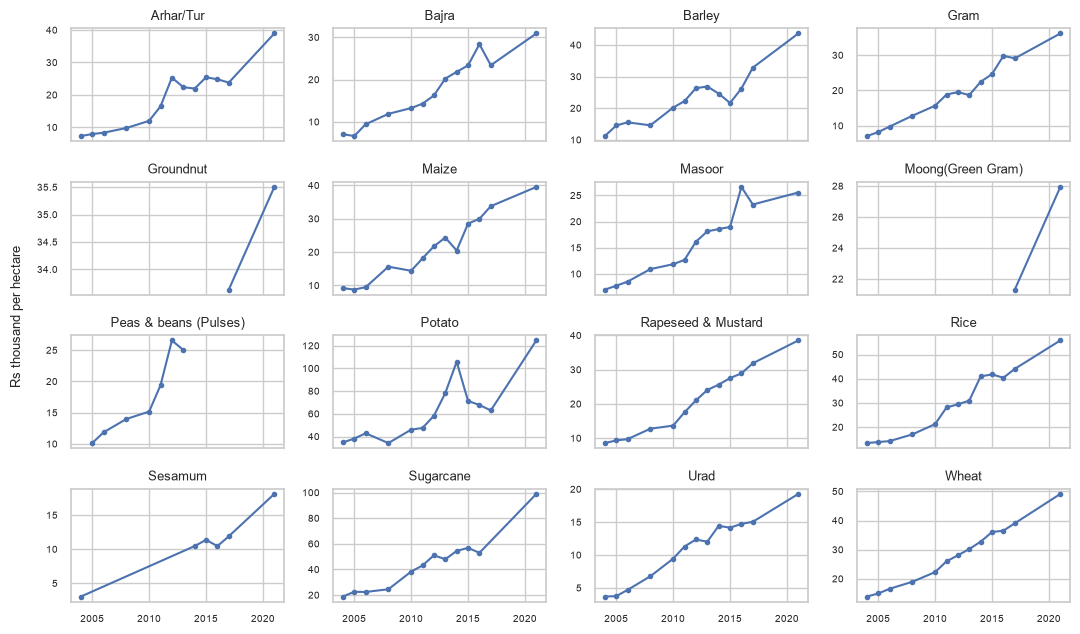

In [11]:
wide = df.pivot(index="crop_year_start", columns="crop", values="cost")

fig, axes = plt.subplots(4, 4, figsize=(11, 6.5), sharex=True)
for ax, crop in zip(axes.ravel(), wide.columns):
    line = wide[crop].dropna()
    ax.plot(line.index, line / 1000, marker="o", ms=3)
    ax.set_title(crop, fontsize=9)
    ax.tick_params(labelsize=7)
fig.supylabel("Rs thousand per hectare", fontsize=9)
plt.tight_layout()
plt.show()

### What the full cost is made of, latest survey of each crop

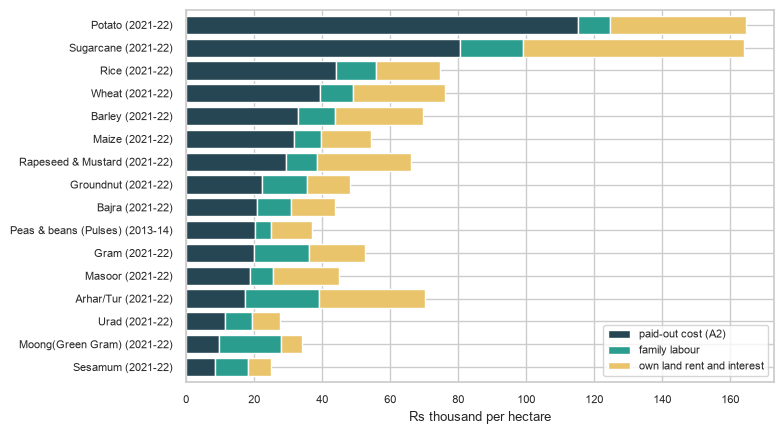

In [12]:
latest = df.dropna(subset=["cost"]).sort_values("crop_year_start").groupby("crop").tail(1).set_index("crop")

parts = pd.DataFrame({"paid-out cost (A2)": latest["cost_a2"], "family labour": latest["family_labour"],
                      "own land rent and interest": latest["cost_c2"] - latest["cost"]}) / 1000
parts.index = parts.index + " (" + latest["crop_year"] + ")"
ax = parts.sort_values("paid-out cost (A2)").plot.barh(stacked=True, figsize=(8, 4.5), width=0.8, color=["#264653", "#2a9d8f", "#e9c46a"])
ax.set_xlabel("Rs thousand per hectare", fontsize=9)
ax.set_ylabel("")
ax.tick_params(labelsize=8)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Return over cost in the survey itself: value of output minus A2+FL (Rs thousand per hectare)

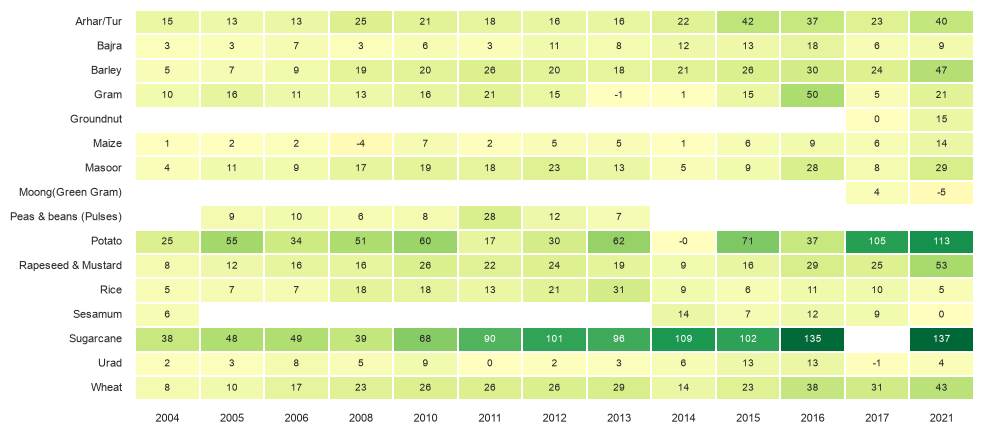

In [13]:
survey_return = (df["value_main_product"] + df["value_by_product"] - df["cost"]) / 1000
survey_return = survey_return.groupby([df["crop"], df["crop_year_start"]]).first().unstack()

plt.figure(figsize=(10, 4.5))
ax = sns.heatmap(survey_return, annot=True, fmt=".0f", cmap="RdYlGn", center=0, annot_kws={"size": 7}, cbar=False, linewidths=0.3)
ax.grid(False)
plt.xlabel("")
plt.ylabel("")
plt.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

## Projecting the Cost to the Coming Season

### Season to project to: the season of the price model

In [14]:
next_label = joblib.load("models/model_b.joblib")["next_season_label"]
target_year = int(next_label[:4])
print("Latest survey:", df["crop_year"].max(), "| cost is projected to", next_label)

Latest survey: 2021-22 | cost is projected to 2026-27


### MSP by crop and year; an MSP not yet in the table grows as it did the year before

In [15]:
msp = pd.read_csv("data/processed/msp.csv").pivot(index="crop_year_start", columns="crop", values="msp_rs_per_quintal")
print("MSP table ends at crop year", msp.index.max())
for year in range(msp.index.max() + 1, target_year + 1):
    msp.loc[year] = msp.loc[year - 1] ** 2 / msp.loc[year - 2]

msp_index = (msp / msp.shift(1)).median(axis=1).fillna(1).cumprod()
msp_index.tail(6).round(3)

MSP table ends at crop year 2025


crop_year_start
2021    5.779
2022    6.093
2023    6.508
2024    6.911
2025    7.314
2026    7.741
dtype: float64

### Growth of the cost and of the MSP

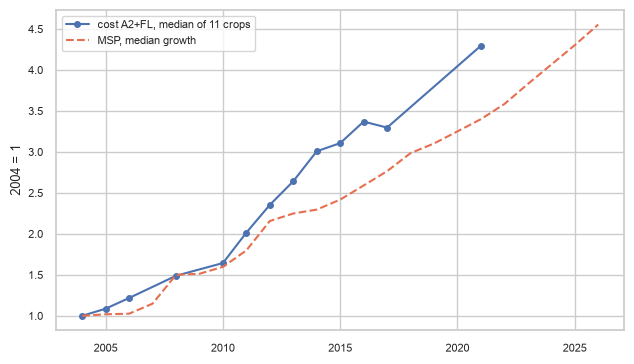

In [16]:
every_survey = wide.columns[wide.notna().all()]
cost_index = (wide[every_survey] / wide[every_survey].iloc[0]).median(axis=1)
first_year = wide.index.min()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(cost_index.index, cost_index, marker="o", ms=4, label=f"cost A2+FL, median of {len(every_survey)} crops")
ax.plot(msp_index.loc[first_year:].index, msp_index.loc[first_year:] / msp_index[first_year], ls="--", color="#e76f51", label="MSP, median growth")
ax.set_ylabel(f"{first_year} = 1", fontsize=9)
ax.tick_params(labelsize=8)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Five ways to project a surveyed cost forward

In [17]:
def growth_rate(series, base):
    series = series.loc[base - 8:base].dropna()
    if len(series) < 2:
        return np.nan
    return (series.iloc[-1] / series.iloc[0]) ** (1 / (series.index[-1] - series.index[0]))


def no_change(crop, base, target):
    return 1.0


def own_trend(crop, base, target):
    return growth_rate(wide[crop], base) ** (target - base)


def all_crop_trend(crop, base, target):
    return np.nanmedian([growth_rate(wide[c], base) for c in wide.columns]) ** (target - base)


def median_msp_growth(crop, base, target):
    return msp_index[target] / msp_index[base]


def crop_msp_growth(crop, base, target):
    if crop not in msp.columns:
        return median_msp_growth(crop, base, target)
    return msp.at[target, crop] / msp.at[base, crop]


METHODS = {"No change": no_change, "Crop's own trend": own_trend, "All-crop trend": all_crop_trend,
           "MSP growth of the crop": crop_msp_growth, "Median MSP growth": median_msp_growth}

### Backtest: project each survey 4 to 5 years ahead and compare with the later survey

In [18]:
def backtest(gaps):
    rows = []
    for base in wide.index:
        for target in wide.index:
            if target - base not in gaps:
                continue
            for crop in wide.columns:
                if pd.isna(wide.at[base, crop]) or pd.isna(wide.at[target, crop]):
                    continue
                row = {"crop": crop, "base": base, "target": target, "actual": wide.at[target, crop]}
                for name, method in METHODS.items():
                    row[name] = wide.at[base, crop] * method(crop, base, target)
                rows.append(row)
    return pd.DataFrame(rows)


tests = backtest(range(4, 6)).dropna()
errors = tests[list(METHODS)].div(tests["actual"], axis=0) - 1
backtest_scores = pd.DataFrame({"MAPE_%": errors.abs().mean() * 100, "median_error_%": errors.abs().median() * 100,
                                "within_20%": (errors.abs() <= 0.20).mean() * 100, "bias_%": errors.mean() * 100}).round(1)
print(len(tests), "projections, from surveys of", tests["base"].min(), "to", tests["base"].max())
backtest_scores.sort_values("MAPE_%")

171 projections, from surveys of 2005 to 2017


,MAPE_%,median_error_%,within_20%,bias_%
Median MSP growth,14.0,11.9,72.5,-4.5
MSP growth of the crop,15.2,12.8,72.5,-2.6
All-crop trend,17.1,13.2,69.6,5.2
Crop's own trend,25.8,20.5,48.5,8.4
No change,32.5,33.2,15.8,-32.1


### Choose the method with the lowest backtest error

In [19]:
COST_METHOD = backtest_scores["MAPE_%"].idxmin()
project = METHODS[COST_METHOD]
print("Chosen:", COST_METHOD)

Chosen: Median MSP growth


### Backtest error by crop

In [20]:
chosen_error = errors[COST_METHOD]
by_crop = pd.DataFrame({"backtests": chosen_error.groupby(tests["crop"]).size(),
                        "MAPE_%": chosen_error.abs().groupby(tests["crop"]).mean() * 100,
                        "bias_%": chosen_error.groupby(tests["crop"]).mean() * 100}).round(1)
by_crop.sort_values("MAPE_%")

,backtests,MAPE_%,bias_%
crop,,,
Wheat,14,5.7,-0.7
Gram,14,8.6,-6.5
Maize,14,8.7,-7.0
Rice,14,11.3,-10.3
Urad,14,11.5,-7.9
Rapeseed & Mustard,14,12.0,-9.1
Sugarcane,11,13.4,-6.5
Masoor,14,13.6,-2.1
Bajra,14,15.2,-6.9


### Error by number of years projected

In [21]:
every = backtest(range(1, 18)).dropna(subset=[COST_METHOD])
every_error = every[COST_METHOD] / every["actual"] - 1
years_ahead = pd.cut(every["target"] - every["base"], [0, 1, 3, 5, 8, 12, 17])
pd.DataFrame({"projections": every_error.groupby(years_ahead).size(), "MAPE_%": every_error.abs().groupby(years_ahead).mean() * 100,
              "within_20%": (every_error.abs() <= 0.20).groupby(years_ahead).mean() * 100,
              "bias_%": every_error.groupby(years_ahead).mean() * 100}).round(1)

,projections,MAPE_%,within_20%,bias_%
"(0, 1]",114,9.6,89.5,-1.7
"(1, 3]",200,14.9,75.5,-1.0
"(3, 5]",186,14.0,74.2,-3.7
"(5, 8]",221,14.9,68.3,-7.5
"(8, 12]",180,19.1,57.8,-10.1
"(12, 17]",61,20.7,50.8,-16.6


### Cost range: where 80% of the actual costs fell around the projection, by years projected

In [22]:
def cost_errors(years_ahead, before=None):
    rows = every[(every["target"] - every["base"]).isin([years_ahead - 1, years_ahead])]
    if before:
        rows = rows[rows["target"] < before]
    return np.log(rows["actual"] / rows[COST_METHOD])


years_projected = target_year - latest["crop_year_start"]
cost_range = pd.DataFrame({years: cost_errors(years).quantile([0.10, 0.90]) for years in sorted(years_projected.unique())}).T
for years, row in cost_range.iterrows():
    print(f"Projected {years - 1} to {years} years ({len(cost_errors(years))} backtests): "
          f"80% of actual costs were between {np.exp(row[0.10]) - 1:+.0%} and {np.exp(row[0.90]) - 1:+.0%} of the projection")

Projected 4 to 5 years (186 backtests): 80% of actual costs were between -15% and +32% of the projection
Projected 12 to 13 years (48 backtests): 80% of actual costs were between -6% and +54% of the projection


## Cost Table for the Coming Season

### Latest survey of each crop, projected

In [23]:
factor = pd.Series({crop: project(crop, int(year), target_year) for crop, year in latest["crop_year_start"].items()})
recent_share = df.sort_values("crop_year_start").groupby("crop")["byproduct_share"].apply(lambda s: s.tail(3).median())

cost_table = pd.DataFrame({
    "survey_year": latest["crop_year"],
    "years_projected": years_projected,
    "holdings_in_survey": latest["holdings_in_sample"].astype(int),
    "surveyed_cost_rs_per_ha": latest["cost"].round(0),
    "growth_factor": factor.round(3),
    "cost_rs_per_ha": (latest["cost"] * factor).round(-2),
    "cost_range_low": (latest["cost"] * factor * np.exp(years_projected.map(cost_range[0.10]))).round(-2),
    "cost_range_high": (latest["cost"] * factor * np.exp(years_projected.map(cost_range[0.90]))).round(-2),
    "paid_out_cost_rs_per_ha": (latest["cost_a2"] * factor).round(-2),
    "total_cost_c2_rs_per_ha": (latest["cost_c2"] * factor).round(-2),
    "byproduct_share": recent_share.round(3),
    "backtests": by_crop["backtests"].reindex(latest.index).fillna(0).astype(int),
    "backtest_error_%": by_crop["MAPE_%"].reindex(latest.index),
})
cost_table.sort_values("cost_rs_per_ha", ascending=False)

,survey_year,years_projected,holdings_in_survey,surveyed_cost_rs_per_ha,growth_factor,cost_rs_per_ha,cost_range_low,cost_range_high,paid_out_cost_rs_per_ha,total_cost_c2_rs_per_ha,byproduct_share,backtests,backtest_error_%
Potato,2021-22,5,120,124649.0,1.340,167000.0,141700.0,220400.0,154300.0,220500.0,0.000,14,26.8
Sugarcane,2021-22,5,185,98968.0,1.340,132600.0,112500.0,175000.0,108000.0,219900.0,0.043,11,13.4
Rice,2021-22,5,487,55810.0,1.340,74800.0,63400.0,98700.0,59000.0,100000.0,0.063,14,11.3
Wheat,2021-22,5,660,49125.0,1.340,65800.0,55800.0,86900.0,52700.0,101700.0,0.215,14,5.7
Barley,2021-22,5,17,43643.0,1.340,58500.0,49600.0,77200.0,43900.0,93100.0,0.246,14,19.0
Maize,2021-22,5,18,39536.0,1.340,53000.0,44900.0,69900.0,42400.0,72900.0,0.158,14,8.7
Arhar/Tur,2021-22,5,7,38956.0,1.340,52200.0,44300.0,68900.0,23000.0,94200.0,0.174,14,20.4
Rapeseed & Mustard,2021-22,5,328,38526.0,1.340,51600.0,43800.0,68100.0,39300.0,88400.0,0.067,14,12.0
Peas & beans (Pulses),2013-14,13,65,25033.0,2.025,50700.0,47900.0,78200.0,41100.0,74900.0,0.060,4,17.4
Gram,2021-22,5,65,36166.0,1.340,48400.0,41100.0,63900.0,26600.0,70600.0,0.061,14,8.6


### Reliable costs: surveyed in the latest year, at least 30 holdings, backtest error within 20%

In [24]:
cost_table["cost_reliable"] = ((latest["crop_year_start"] == df["crop_year_start"].max())
                               & (cost_table["holdings_in_survey"] >= 30)
                               & (cost_table["backtests"] >= 5)
                               & (cost_table["backtest_error_%"] <= 20))
print("Reliable:", sorted(cost_table.index[cost_table["cost_reliable"]]))
print("Not reliable:", sorted(cost_table.index[~cost_table["cost_reliable"]]))

Reliable: ['Bajra', 'Gram', 'Rapeseed & Mustard', 'Rice', 'Sugarcane', 'Urad', 'Wheat']
Not reliable: ['Arhar/Tur', 'Barley', 'Groundnut', 'Maize', 'Masoor', 'Moong(Green Gram)', 'Peas & beans (Pulses)', 'Potato', 'Sesamum']


## Profit Range

### Past predictions of yield and of price for the same district, crop, season and year

In [25]:
KEYS = ["district", "crop", "season", "crop_year_start", "sample"]
yield_past = joblib.load("models/model_a.joblib")["past_predictions"]
price_past = joblib.load("models/model_b.joblib")["past_predictions"]

both = yield_past.merge(price_past, on=KEYS, suffixes=("_yield", "_price"))
both["error_yield"] = np.log(both["actual_yield"] / both["predicted_yield"])
both["error_price"] = np.log(both["actual_price"] / both["predicted_price"])
both["error_revenue"] = both["error_yield"] + both["error_price"]

print(f"{len(yield_past):,} yield predictions | {len(price_past):,} price predictions | {len(both):,} rows with both")
both.groupby("sample")["crop_year_start"].agg(["min", "max", "size"])

25,683 yield predictions | 8,102 price predictions | 7,021 rows with both


,min,max,size
sample,,,
cross-validation,2011,2019,4417
test,2020,2024,2604


### Yield errors and price errors of the same crop and year partly cancel

In [26]:
pd.DataFrame({"rows": both.groupby("crop").size(),
              "correlation": both.groupby("crop").apply(lambda g: g["error_yield"].corr(g["error_price"])),
              "yield_error_spread": both.groupby("crop")["error_yield"].std(),
              "price_error_spread": both.groupby("crop")["error_price"].std(),
              "revenue_error_spread": both.groupby("crop")["error_revenue"].std()}).round(2).sort_values("correlation")

,rows,correlation,yield_error_spread,price_error_spread,revenue_error_spread
crop,,,,,
Potato,807,-0.31,0.23,0.37,0.37
Arhar/Tur,271,-0.25,0.34,0.21,0.35
Rapeseed & Mustard,858,-0.22,0.28,0.11,0.28
Masoor,382,-0.15,0.34,0.11,0.34
Sesamum,70,-0.13,0.54,0.19,0.55
Bajra,221,-0.12,0.25,0.16,0.28
Urad,504,-0.11,0.32,0.18,0.35
Barley,356,-0.09,0.21,0.10,0.23
Moong(Green Gram),394,-0.08,0.33,0.12,0.34


### Three ways to combine the yield error and the price error into a revenue error

In [27]:
LEVELS = np.arange(1, 100)
MIN_ROWS = 100


def at_levels(errors):
    return np.quantile(errors, LEVELS / 100)


def worst_with_worst(rows):
    return at_levels(rows["error_yield"]) + at_levels(rows["error_price"])


def independent(rows):
    return at_levels(np.add.outer(at_levels(rows["error_yield"]), at_levels(rows["error_price"])))


def as_they_happened(rows):
    return at_levels(rows["error_revenue"])


RANGE_METHODS = {"Worst yield with worst price": worst_with_worst, "Independent errors": independent,
                 "Errors as they happened together": as_they_happened}


def revenue_errors(method, rows):
    table = {crop: method(group) for crop, group in rows.groupby("crop") if len(group) >= MIN_ROWS}
    return pd.DataFrame({**table, "other crops": method(rows)}, index=LEVELS)


def crop_column(table, crops):
    return crops.where(crops.isin(table.columns), "other crops")


def inside_range(table, rows):
    column = crop_column(table, rows["crop"])
    return (rows["error_revenue"] >= column.map(table.loc[10])) & (rows["error_revenue"] <= column.map(table.loc[90]))

### Cross-validation: build the 80% range on two blocks of years, check it on the third

In [28]:
cv = both[both["sample"] == "cross-validation"]
block = pd.cut(cv["crop_year_start"], [2010, 2013, 2016, 2019], labels=["2011-2013", "2014-2016", "2017-2019"])

cv_inside = pd.DataFrame({name: {held_out: inside_range(revenue_errors(method, cv[block != held_out]), cv[block == held_out]).mean() * 100
                                 for held_out in block.cat.categories}
                          for name, method in RANGE_METHODS.items()})
range_scores = pd.DataFrame({"inside_range_%": cv_inside.mean(), "miss_from_80": (cv_inside - 80).abs().mean()})
display(cv_inside.round(1))
range_scores.round(1)

,Worst yield with worst price,Independent errors,Errors as they happened together
2011-2013,93.9,87.6,87.3
2014-2016,69.2,56.9,57.0
2017-2019,91.2,81.7,77.8


,inside_range_%,miss_from_80
Worst yield with worst price,84.8,12.0
Independent errors,75.4,10.8
Errors as they happened together,74.0,10.8


### Choose the method whose range misses 80% the least

In [29]:
RANGE_METHOD = range_scores["miss_from_80"].idxmin()
revenue_error = revenue_errors(RANGE_METHODS[RANGE_METHOD], cv)
print("Chosen:", RANGE_METHOD)

Chosen: Independent errors


### Check on the test years

In [30]:
test = both[both["sample"] == "test"]
test_inside = pd.DataFrame({name: inside_range(revenue_errors(method, cv), test) for name, method in RANGE_METHODS.items()})
print("Actual revenue inside the range:", (test_inside.mean() * 100).round(1).to_dict())
print("By test year:", (test_inside[RANGE_METHOD].groupby(test["crop_year_start"]).mean() * 100).round(1).to_dict())

Actual revenue inside the range: {'Worst yield with worst price': 95.8, 'Independent errors': 90.1, 'Errors as they happened together': 89.2}
By test year: {2020: 86.4, 2021: 92.6, 2022: 90.5, 2023: 90.0, 2024: 91.0}


### Revenue range by crop

In [31]:
cv_rows = cv.groupby("crop").size()
column = crop_column(revenue_error, cv_rows.index.to_series())
revenue_range = pd.DataFrame({"cv_rows": cv_rows,
                              "errors_used": np.where(column == "other crops", "all crops together", "the crop's own"),
                              "range_low_%": (np.exp(column.map(revenue_error.loc[10])) - 1) * 100,
                              "range_high_%": (np.exp(column.map(revenue_error.loc[90])) - 1) * 100,
                              "test_rows": test.groupby("crop").size(),
                              "test_inside_range_%": test_inside[RANGE_METHOD].groupby(test["crop"]).mean() * 100}).round(1)
revenue_range.sort_values("range_low_%")

,cv_rows,errors_used,range_low_%,range_high_%,test_rows,test_inside_range_%
crop,,,,,,
Gram,380,the crop's own,-52.4,76.6,274,97.1
Potato,592,the crop's own,-45.5,76.9,215,100.0
Arhar/Tur,183,the crop's own,-41.9,63.1,88,97.7
Moong(Green Gram),220,the crop's own,-37.8,43.4,174,88.5
Peas & beans (Pulses),185,the crop's own,-36.0,55.1,71,97.2
Urad,289,the crop's own,-35.7,53.0,215,88.4
Masoor,202,the crop's own,-34.0,54.7,180,91.1
Jowar,13,all crops together,-32.1,49.1,13,69.2
Sesamum,39,all crops together,-32.1,49.1,31,61.3


### Cost error of each crop, for the number of years its cost is projected

In [32]:
cost_error = pd.DataFrame({crop: at_levels(cost_errors(years)) for crop, years in years_projected.items()}, index=LEVELS)
(np.exp(cost_error.loc[[10, 50, 90]]) - 1).T.mul(100).round(0).drop_duplicates()

,10,50,90
Peas & beans (Pulses),-6.0,26.0,54.0
Bajra,-15.0,5.0,32.0


### Check on 2021-22, the one test year with a cost survey: predicted and actual profit

In [33]:
base = {crop: wide.loc[2016:2017, crop].last_valid_index() for crop in wide.columns}
year_check = pd.DataFrame({"base": base, "actual_cost": wide.loc[2021]}).dropna()
year_check["projected_cost"] = [wide.at[year, crop] * project(crop, int(year), 2021) for crop, year in year_check["base"].items()]
year_check["share"] = [df[(df["crop"] == crop) & (df["crop_year_start"] <= year)].sort_values("crop_year_start")["byproduct_share"].tail(3).median()
                       for crop, year in year_check["base"].items()]
earlier_cost_error = at_levels(cost_errors(5, before=2021))

check = test[test["crop_year_start"] == 2021].join(year_check, on="crop", how="inner")
per_tonne = check["crop"].map(SOLD_TONNES_PER_TONNE_OF_YIELD).fillna(1) * 10 * (1 + check["share"])
check["predicted_profit"] = check["predicted_yield"] * check["predicted_price"] * per_tonne - check["projected_cost"]
check["actual_profit"] = check["actual_yield"] * check["actual_price"] * per_tonne - check["actual_cost"]
bounds = np.array([profit_range(row["predicted_profit"] + row["projected_cost"], row["projected_cost"],
                                revenue_error[column], earlier_cost_error)
                   for (_, row), column in zip(check.iterrows(), crop_column(revenue_error, check["crop"]))])
check["inside"] = (check["actual_profit"] >= bounds[:, 0]) & (check["actual_profit"] <= bounds[:, 1])
check["below"] = check["actual_profit"] < bounds[:, 0]

print(f"{len(check)} district-crop rows of 2021-22 | actual profit inside the range: {check['inside'].mean():.1%} | below it: {check['below'].mean():.1%}")
check.groupby("crop").agg(rows=("inside", "size"), predicted_profit=("predicted_profit", "median"), actual_profit=("actual_profit", "median"),
                          inside_pct=("inside", lambda s: s.mean() * 100), below_pct=("below", lambda s: s.mean() * 100)).round(0)

533 district-crop rows of 2021-22 | actual profit inside the range: 93.6% | below it: 2.4%


,rows,predicted_profit,actual_profit,inside_pct,below_pct
crop,,,,,
Arhar/Tur,20,59115.0,54690.0,90.0,10.0
Bajra,18,14971.0,16056.0,100.0,0.0
Barley,29,36721.0,42349.0,100.0,0.0
Gram,56,31049.0,42556.0,88.0,0.0
Maize,30,10386.0,11489.0,97.0,0.0
Masoor,32,40179.0,39949.0,97.0,3.0
Moong(Green Gram),40,31696.0,28531.0,95.0,2.0
Potato,72,275535.0,165161.0,99.0,1.0
Rapeseed & Mustard,66,28548.0,40671.0,82.0,2.0


## Save the Cost Table and the Profit Range

In [34]:
bundle = {
    "cost": cost_table,
    "cost_year_label": next_label,
    "method": COST_METHOD,
    "surveys": (df["crop_year"].min(), df["crop_year"].max()),
    "backtest": {"projections": len(tests), "years_ahead": "4-5", **backtest_scores.loc[COST_METHOD].to_dict()},
    "profit_range": {"interval": (0.10, 0.90), "method": RANGE_METHOD, "revenue_error": revenue_error, "cost_error": cost_error,
                     "revenue_inside_range_%": {"cross_validation": round(float(range_scores.at[RANGE_METHOD, "inside_range_%"]), 1),
                                                "test": round(float(test_inside[RANGE_METHOD].mean() * 100), 1)}},
}
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle, "models/cost.joblib")
print("Saved models/cost.joblib |", len(cost_table), "crops | cost for", next_label, "|", COST_METHOD, "|", bundle["backtest"])
print("Profit range:", RANGE_METHOD, "|", bundle["profit_range"]["revenue_inside_range_%"])

Saved models/cost.joblib | 16 crops | cost for 2026-27 | Median MSP growth | {'projections': 171, 'years_ahead': '4-5', 'MAPE_%': 14.0, 'median_error_%': 11.9, 'within_20%': 72.5, 'bias_%': -4.5}
Profit range: Independent errors | {'cross_validation': 75.4, 'test': 90.1}


### Check the saved table through the interface functions

In [35]:
estimate_costs()

,survey_year,years_projected,holdings_in_survey,surveyed_cost_rs_per_ha,growth_factor,cost_rs_per_ha,cost_range_low,cost_range_high,paid_out_cost_rs_per_ha,total_cost_c2_rs_per_ha,byproduct_share,backtests,backtest_error_%,cost_reliable,cost_year
Arhar/Tur,2021-22,5,7,38956.0,1.340,52200.0,44300.0,68900.0,23000.0,94200.0,0.174,14,20.4,False,2026-27
Bajra,2021-22,5,103,30920.0,1.340,41400.0,35100.0,54700.0,28100.0,58500.0,0.295,14,15.2,True,2026-27
Barley,2021-22,5,17,43643.0,1.340,58500.0,49600.0,77200.0,43900.0,93100.0,0.246,14,19.0,False,2026-27
Gram,2021-22,5,65,36166.0,1.340,48400.0,41100.0,63900.0,26600.0,70600.0,0.061,14,8.6,True,2026-27
Groundnut,2021-22,5,45,35504.0,1.340,47600.0,40400.0,62800.0,29900.0,64300.0,0.028,0,NaN,False,2026-27
Maize,2021-22,5,18,39536.0,1.340,53000.0,44900.0,69900.0,42400.0,72900.0,0.158,14,8.7,False,2026-27
Masoor,2021-22,5,6,25559.0,1.340,34200.0,29100.0,45200.0,25100.0,60200.0,0.034,14,13.6,False,2026-27
Moong(Green Gram),2021-22,5,21,27942.0,1.340,37400.0,31800.0,49400.0,13100.0,45600.0,0.045,0,NaN,False,2026-27
Peas & beans (Pulses),2013-14,13,65,25033.0,2.025,50700.0,47900.0,78200.0,41100.0,74900.0,0.060,4,17.4,False,2026-27
Potato,2021-22,5,120,124649.0,1.340,167000.0,141700.0,220400.0,154300.0,220500.0,0.000,14,26.8,False,2026-27


### Crops ranked by profit (rice is sold as paddy: 1 t of rice = 1.5 t of paddy)

In [36]:
SHOWN = ["farm_predicted_t_ha", "sold_t_ha", "predicted_price", "revenue_rs_per_ha", "byproduct_rs_per_ha",
         "cost_rs_per_ha", "cost_reliable", "profit_rs_per_ha", "profit_range_low", "profit_range_high"]

agra = recommend_crops("Agra", "Rabi", farmer_yields={"Wheat": 3.6})
agra[SHOWN]

,farm_predicted_t_ha,sold_t_ha,predicted_price,revenue_rs_per_ha,byproduct_rs_per_ha,cost_rs_per_ha,cost_reliable,profit_rs_per_ha,profit_range_low,profit_range_high
crop,,,,,,,,,,
Peas & beans (Pulses),2.12,2.12,7112.0,150800.0,9000.0,50700.0,False,109100.0,37900.0,185000.0
Rapeseed & Mustard,1.68,1.68,7301.0,122700.0,8200.0,51600.0,True,79300.0,32000.0,119300.0
Gram,1.45,1.45,7879.0,114200.0,7000.0,48400.0,True,72800.0,7800.0,161000.0
Potato,31.29,31.29,688.0,215300.0,0.0,167000.0,False,48300.0,-63100.0,205800.0
Wheat,3.58,3.58,2548.0,91200.0,19600.0,65800.0,True,45000.0,12900.0,71900.0
Masoor,0.89,0.89,6927.0,61700.0,2100.0,34200.0,False,29600.0,4500.0,62700.0
Barley,2.67,2.67,2288.0,61100.0,15000.0,58500.0,False,17600.0,-9700.0,42400.0
Onion,14.46,14.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Garlic,5.33,5.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Revenue split into cost and profit

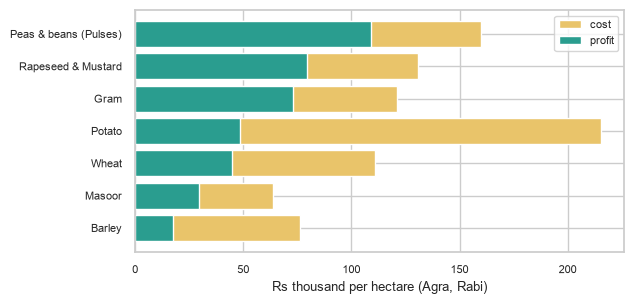

In [37]:
shown = agra.dropna(subset=["profit_rs_per_ha"]).sort_values("profit_rs_per_ha")
earned = (shown["revenue_rs_per_ha"] + shown["byproduct_rs_per_ha"]) / 1000

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(shown.index, earned, color="#e9c46a", label="cost")
ax.barh(shown.index, shown["profit_rs_per_ha"] / 1000, color="#2a9d8f", label="profit")
ax.set_xlabel("Rs thousand per hectare (Agra, Rabi)", fontsize=9)
ax.tick_params(labelsize=8)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Profit with its range

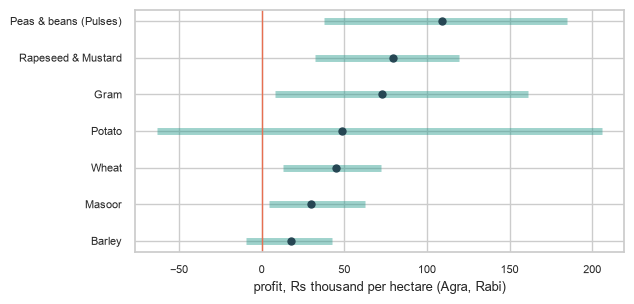

In [38]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hlines(shown.index, shown["profit_range_low"] / 1000, shown["profit_range_high"] / 1000, color="#2a9d8f", lw=5, alpha=0.45)
ax.plot(shown["profit_rs_per_ha"] / 1000, shown.index, "o", color="#264653", ms=5)
ax.axvline(0, color="#e76f51", lw=1)
ax.set_xlabel("profit, Rs thousand per hectare (Agra, Rabi)", fontsize=9)
ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

In [39]:
recommend_crops("Gorakhpur", "Kharif")[SHOWN]

,farm_predicted_t_ha,sold_t_ha,predicted_price,revenue_rs_per_ha,byproduct_rs_per_ha,cost_rs_per_ha,cost_reliable,profit_rs_per_ha,profit_range_low,profit_range_high
crop,,,,,,,,,,
Arhar/Tur,1.08,1.08,7921.0,85500.0,14900.0,52200.0,False,48200.0,1400.0,107300.0
Urad,0.63,0.63,8990.0,56600.0,2300.0,25800.0,True,33100.0,9800.0,62400.0
Rice,2.80,4.20,2357.0,99000.0,6200.0,74800.0,True,30400.0,7400.0,61100.0
Bajra,2.04,2.04,2135.0,43600.0,12900.0,41400.0,True,15100.0,-1800.0,38100.0
Sesamum,0.29,0.29,11146.0,32300.0,1400.0,24300.0,False,9400.0,-4100.0,24900.0
Moong(Green Gram),0.40,0.40,8748.0,35000.0,1600.0,37400.0,False,-800.0,-19800.0,14400.0
Maize,1.99,1.99,2135.0,42500.0,6700.0,53000.0,False,-3800.0,-23700.0,14800.0
Jowar,1.77,1.77,2849.0,50400.0,NaN,NaN,NaN,NaN,NaN,NaN
Groundnut,1.25,1.25,NaN,NaN,NaN,47600.0,False,NaN,NaN,NaN
